# Import data of possible binary AGN candidates

## Download published SMBH-binary candidate catalogues from VizieR

Catalogues:

    1. foustoul2025 (https://www.aanda.org/articles/aa/pdf/2025/07/aa52818-24.pdf)
    2. graham2015

In [22]:
from astroquery.vizier import Vizier
from pathlib import Path
import pandas as pd
import requests
from io import StringIO
import matplotlib.pyplot as plt
plt.style.use("../src/light.mplstyle")

In [10]:
# use Harvard vizier server, since Strasbourg didnt work
vizier = Vizier(
    columns=["**"],
    row_limit=-1,
    vizier_server="vizier.cfa.harvard.edu",
    timeout=120
)



# download data from foustoul2025 table c1 (weak candidates)
"""
tables = vizier.get_catalogs(
    "J/A+A/699/A55/tablec1"
)
"""

tables = vizier.get_catalogs("J/A+A/699/A55")
print(tables.keys())

df = tables[0].to_pandas()

df = df.rename(columns={
    "Name": "ztf_oid",
    "RAJ2000": "ra",
    "DEJ2000": "dec",
    "Per": "period_days",
    "z": "redshift"
})

print(df.head())
print("Number of candidates:", len(df))

Path("data").mkdir(exist_ok=True)

df.to_csv(
    "../data/catalogs/foustoul2025_weak_candidates.csv",
    index=False
)


['J/A+A/699/A55/tablec1']
   recno          ztf_oid        ra      dec  redshift  period_days  \
0      1  722214100002451  246.1833  43.9945      1.93  1517.199951   
1      2  762207400010289  253.4480  46.5943      2.29  1547.900024   
2      3  796215300002648  254.9410  57.5255      2.06  1354.800049   
3      4  721210400000714  237.5624  41.4187      1.89  1527.599976   
4      5  760213300014840  237.5921  49.7842      2.09  1545.900024   

        e_Per  logMBH  e_logMBH  rchi2 CRTSobs  
0   55.799999    9.24      0.02   1.09      No  
1  650.799988    8.12      0.15   1.23     Yes  
2   45.299999     NaN       NaN   0.92      No  
3  720.700012    8.82      0.05   1.22     Yes  
4  722.799988    8.69      0.08   1.03     Yes  
Number of candidates: 221


## Recieve lightcurves of candidates

In [ ]:
# read one example candidate from saved catalogs
catalog = pd.read_csv("../data/catalogs/foustoul2025_weak_candidates.csv", dtype={"ztf_oid": "string"})
#print(catalog.head())
print(catalog.columns)

# download lightcurve from ZTF
oid = str(catalog.iloc[0]["ztf_oid"])
url = "https://irsa.ipac.caltech.edu/cgi-bin/ZTF/nph_light_curves"
params = {
    "ID": oid,
    "FORMAT": "csv",
    "BAD_CATFLAGS_MASK": 32768
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()
lc = pd.read_csv(StringIO(response.text), comment="#")

Index(['recno', 'ztf_oid', 'ra', 'dec', 'redshift', 'period_days', 'e_Per',
       'logMBH', 'e_logMBH', 'rchi2', 'CRTSobs'],
      dtype='str')


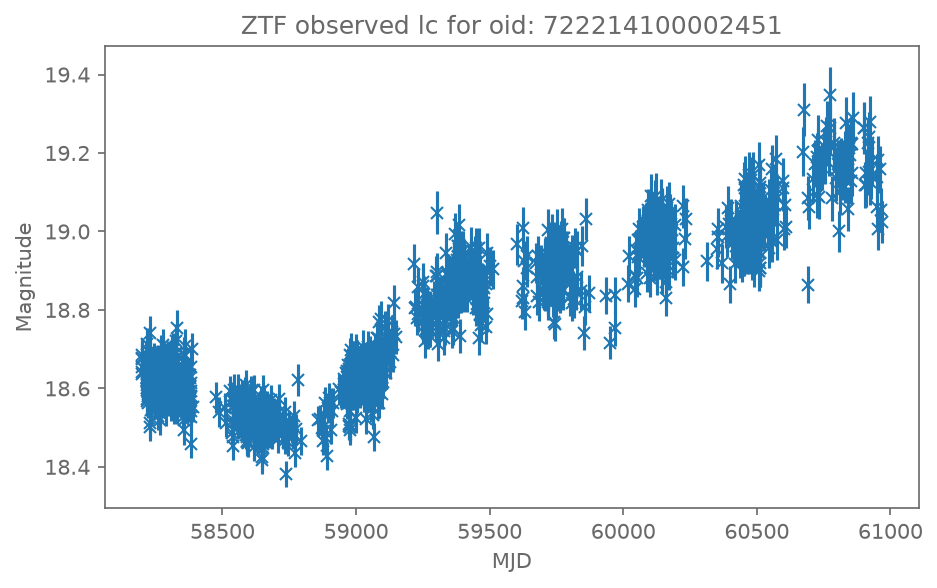

In [25]:
# plot lc from example
plt.figure(dpi=150)
plt.title(f"ZTF observed lc for oid: {oid}")
plt.errorbar(lc["mjd"], lc["mag"], yerr=lc["magerr"], fmt="x")
plt.gca().invert_yaxis
plt.xlabel("MJD")
plt.ylabel("Magnitude")
plt.show()